**Цель работы:** Пройти полный цикл решения задачи классификации: от анализа данных и построения baseline до сравнения нескольких алгоритмов, анализа метрик, ошибок и важности признаков.

**Минимальный порог качества: F1 > 0.70**

F1-score - это метрика качества классификации, которая объединяет Precision и Recall в одно число. Она показывает, насколько хорошо модель находит положительный класс, при этом не делая слишком много ложных срабатываний.

# Данные

- Провести первичный анализ данных
- После основных результатов должны быть краткие содержательные выводы


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer  # заполнение пропусков (медианой / самым частым)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)  # confusion_matrix — матрица ошибок

RS = 42 # воспроизводимость
df = pd.read_csv("data/Titanic-Dataset.csv")

print("Размер:", df.shape, "| полных дубликатов:", df.duplicated().sum())
pd.DataFrame({"dtype": df.dtypes, "пропуски": df.isna().sum(), "уникальных": df.nunique()})

Размер: (891, 12) | полных дубликатов: 0


,dtype,пропуски,уникальных
PassengerId,int64,0,891
Survived,int64,0,2
Pclass,int64,0,3
Name,object,0,891
Sex,object,0,2
Age,float64,177,88
SibSp,int64,0,7
Parch,int64,0,7
Ticket,object,0,681
Fare,float64,0,248


{0: 0.616, 1: 0.384}


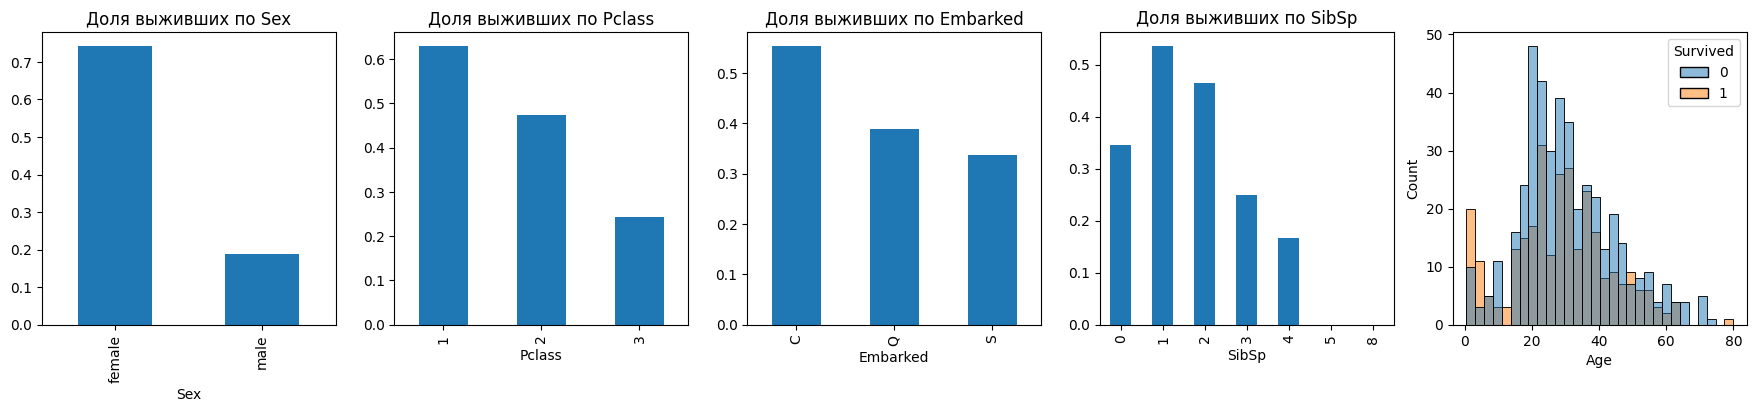

Pclass,1,2,3
Sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


,Age,Fare
count,714.0,891.0
mean,29.7,32.2
std,14.5,49.7
min,0.4,0.0
25%,20.1,7.9
50%,28.0,14.5
75%,38.0,31.0
max,80.0,512.3


In [2]:
print(df["Survived"].value_counts(normalize=True).round(3).to_dict())  # Доля выживших — видим дисбаланс классов

fig, ax = plt.subplots(1, 5, figsize=(22, 3.8))
for a, c in zip(ax[:4], ["Sex", "Pclass", "Embarked", "SibSp"]):
    df.groupby(c)["Survived"].mean().plot.bar(ax=a, title=f"Доля выживших по {c}")
sns.histplot(data=df, x="Age", hue="Survived", bins=30, ax=ax[4])
plt.show()

display(df.groupby(["Sex", "Pclass"])["Survived"].mean().unstack().round(2))  # Таблица долей выживших
display(df[["Age", "Fare"]].describe().round(1))

In [3]:
print("Уникальных значений:", df[["PassengerId", "Name", "Ticket"]].nunique().to_dict())
print("Доля выживших, если Cabin указана / не указана:", df.groupby(df["Cabin"].notna())["Survived"].mean().round(2).to_dict())

Уникальных значений: {'PassengerId': 891, 'Name': 891, 'Ticket': 681}
Доля выживших, если Cabin указана / не указана: {False: 0.3, True: 0.67}


**Выводы по первичному анализу данных**

1. **Размер и пропуски.** В данных 891 пассажир и 12 столбцов; полных дубликатов нет. Пропуски: `Cabin` (≈ 77%), `Age` (≈ 20%) и `Embarked` (2 значения). Пропуски в `Age` слишком многочисленны, чтобы удалять строки (потеряли бы весомую часть данных), а `Cabin` пуст почти у всех - как признак он малопригоден.
2. **Целевая переменная умеренно несбалансирована:** выжили ≈ 38%, погибли ≈ 62%. Модель, всегда отвечающая «не выжил», получит accuracy ≈ 0.62, поэтому одной accuracy оценивать модели нельзя.
3. **Самый сильный сигнал - пол.** Выжили ≈ 74% женщин и ≈ 19% мужчин (политика «женщины и дети - первыми»). Следом идёт класс каюты: выжили ≈ 63% пассажиров 1-го, ≈ 47% 2-го и ≈ 24% 3-го класса. Эти два признака вместе дают сильное разделение (например, женщины 1–2 классов выживали почти всегда, мужчины 2–3 классов - очень редко).
4. **Возраст и семья.** Среди детей (младше ≈ 10–12 лет) доля выживших выше, чем у взрослых, пожилые выживали реже; зависимость немонотонная, что важно для деревьев и невыгодно для линейных моделей. У одиночек и у очень больших семей (`SibSp` ≥ 3) шансы ниже, чем у небольших семей.
5. **Порт посадки** `Embarked`: у Cherbourg (C) доля выживших выше (≈ 55% против ≈ 34% у Southampton), но, вероятно, это следствие состава пассажиров (в C больше пассажиров 1-го класса), а не влияние самого порта.
6. **`Fare` сильно скошен вправо** (медиана ≈ 14, максимум ≈ 512) и тесно связан с `Pclass`. Для деревьев это не проблема, а для SVM и KNN нужно масштабирование.
7. **Признаки, которые нельзя использовать «как есть».**
   - `PassengerId` - просто номер строки, не несёт информации о пассажире; но уникален у каждого объекта, и модель, особенно дерево, может использовать его для запоминания объектов.
   - `Name` и `Ticket` почти уникальны (681 билет на 891 пассажира) - высокая кардинальность, по ним модель «узнаёт» конкретных людей и семьи, а не обобщает закономерности.
   - `Cabin` указана у ≈ 23% пассажиров, и среди них доля выживших ≈ 67% против ≈ 30% у остальных. Дело не в самой каюте: данные о каютах чаще известны именно для выживших (информация собиралась уже после катастрофы), то есть наличие значения само является следствием целевой переменной - это утечка информации. Плюс признак почти пуст и имеет высокую кардинальность.
   
   Все четыре признака исключаем.

# Подготовка данных и выборок

- Обработайте пропущенные значения и категориальные признаки
- Разделитm данные на обучающую и тестовую части с сохранением соотношения классов
- Зафиксировать random_state

In [4]:
X, y = df.drop(columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"]), df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS, stratify=y)  # stratify — сохранить пропорции классов в обеих частях
cv = StratifiedKFold(5, shuffle=True, random_state=RS)

num, cat = ["Pclass", "Age", "SibSp", "Parch", "Fare"], ["Sex", "Embarked"]

def prep(scale=False, num=num):  # scale=False — без масштабирования(для деревьев), scale=True — со StandardScaler(для SVM/KNN)
    num_pipe = make_pipeline(SimpleImputer(strategy="median"), *([StandardScaler()] if scale else [])) 
    cat_pipe = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(drop="if_binary", sparse_output=False))  # sparse_output — вернуть плотную матрицу
    # Для категориальных: заполнить самым частым, one-hot закодировать
    
    return ColumnTransformer([("num", num_pipe, num), ("cat", cat_pipe, cat)])  # ColumnTransformer — применяет разные пайплайны к разным столбцам и объединяет

pp = prep().fit(X_train)
Z = pd.DataFrame(pp.transform(X_train), columns=pp.get_feature_names_out())
print("train:", X_train.shape, "| test:", X_test.shape, "| доля выживших train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
print("Признаки после обработки:", list(Z.columns), "| пропусков:", Z.isna().sum().sum())
print("Медианы train для заполнения пропусков:", dict(zip(num, pp.named_transformers_["num"][0].statistics_.round(1)))) # .statistics_ — вычисленные значения

train: (712, 7) | test: (179, 7) | доля выживших train/test: 0.383 0.385
Признаки после обработки: ['num__Pclass', 'num__Age', 'num__SibSp', 'num__Parch', 'num__Fare', 'cat__Sex_male', 'cat__Embarked_C', 'cat__Embarked_Q', 'cat__Embarked_S'] | пропусков: 0
Медианы train для заполнения пропусков: {'Pclass': np.float64(3.0), 'Age': np.float64(28.5), 'SibSp': np.float64(0.0), 'Parch': np.float64(0.0), 'Fare': np.float64(14.5)}


**Обработка пропусков и категориальных признаков**

- `Age` - заполняем **медианой** по train: пропусков ≈ 20%, удалять строки нельзя, а медиана устойчива к выбросам и скошенному распределению (среднее смещается).
- `Embarked` - 2 пропуска, заполняем **самым частым значением** (`S`): на такой малой доле выбор не влияет на результат.
- `Sex`, `Embarked` - **one-hot кодирование**: категории не упорядочены, числовые коды (0/1/2) навязали бы порядок, который воспримется как реальный. Для бинарного `Sex` оставляем один столбец (`drop="if_binary"`).
- `Pclass` оставляем числовым: три класса упорядочены (1 > 2 > 3 по статусу).
- `PassengerId`, `Name`, `Ticket`, `Cabin` исключены.

**Разбиение:** 80% / 20%, `stratify=y` сохраняет долю выживших (≈ 38%) в обеих частях, `random_state=42`. Все модели обучаются и оцениваются на одном разбиении. Тест небольшой (179 объектов, ≈ 69 выживших), поэтому F1 на нём шумит. Для выбора моделей и параметров используется кросс-валидация на train.

**Утечки при подготовке.** Препроцессинг упакован в `Pipeline` вместе с моделью: медианы, самые частые значения, категории и среднее для масштабирования вычисляются только по обучающей части (при кросс-валидации - только по обучающим фолдам), а к тесту лишь применяются.

**Масштабирование.** Нужно для **SVM и KNN** (оба алгоритма основаны на расстояниях между объектами), поэтому для них в `prep` включается `StandardScaler`. Для **деревьев, случайного леса и бустинга не нужно**: они сравнивают значения признака с порогами, и результат не меняется при монотонных преобразованиях масштаба.

# Baseline 

- Перед обучением моделей построить Dummy baseline, который всегда предсказывает наиболее частый класс. 
- Рассчитать для него те же метрики, что и для остальных моделей

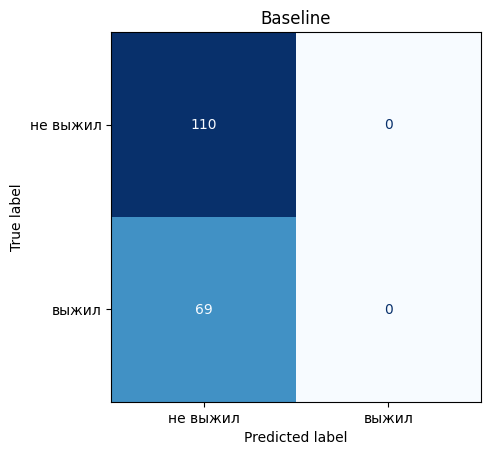

Accuracy     0.615
Precision    0.000
Recall       0.000
F1           0.000
F1_train     0.000
dtype: float64

In [5]:
# Accuracy — доля верных ответов
# Precision — TP / (TP + FP)
# Recall — TP / (TP + FN)
# F1 — гармоническое среднее Precision и Recall
def evaluate(y_true, y_pred):  
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred), "F1": f1_score(y_true, y_pred)}

res, fitted, preds = {}, {}, {}

def fit_eval(name, model):
    fitted[name] = model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    res[name] = {**evaluate(y_test, preds[name]), "F1_train": f1_score(y_train, model.predict(X_train))}
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name], display_labels=["не выжил", "выжил"], cmap="Blues", colorbar=False)
    plt.title(name)
    plt.show()
    return pd.Series(res[name]).round(3)

fit_eval("Baseline", DummyClassifier(strategy="most_frequent"))

Baseline всегда предсказывает самый частый класс («не выжил»). У него accuracy ≈ 0.62 (равна доле погибших), а Recall и F1 по классу «выжил» равны 0: ни один выживший не найден (Precision не определена, так как положительных предсказаний нет). Это показывает, почему accuracy недостаточно: значение 0.62 выглядит приемлемо, хотя модель бесполезна. Любая содержательная модель должна заметно превзойти baseline именно по F1.

# Метрики

- Для оценки моделей использовать:
    - Accuracy
    - Precision
    - Recall
    - F1-score
- Для каждой модели построить confusion matrix

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, preds["Baseline"]).ravel()
# confusion_matrix возвращает матрицу [[TN, FP], [FN, TP]], .ravel() — разворачивает в одномерный массив [TN, FP, FN, TP]

print(f"Baseline: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Accuracy = {(tp + tn) / (tp + tn + fp + fn):.3f}")
print(f"Precision = {tp}/{tp + fp} -> не определена (принимаем 0)")
print(f"Recall = {tp / (tp + fn):.3f}")
print("F1 =", round(f1_score(y_test, preds["Baseline"]), 3))

Baseline: TN=110, FP=0, FN=69, TP=0
Accuracy = 0.615
Precision = 0/0 -> не определена (принимаем 0)
Recall = 0.000
F1 = 0.0


Положительный класс - «пассажир выжил» (1).

- **Accuracy** - доля верных ответов. При несбалансированных классах вводит в заблуждение.
- **Precision** = TP / (TP + FP): какая доля пассажиров, которых модель назвала выжившими, действительно выжила.
- **Recall** = TP / (TP + FN): какую долю реально выживших модель нашла.
- **F1** - среднее гармоническое Precision и Recall; высокое значение только тогда, когда высоки обе метрики, поэтому она «наказывает» перекос в одну сторону (например, модель, которая всем говорит «выжил», получит Recall = 1, но низкую Precision).

- **False Positive** - модель предсказала «выжил», но пассажир погиб (ложная надежда).
- **False Negative** - модель предсказала «погиб», но пассажир выжил (пропущенный выживший). 
FP снижают Precision, FN снижают Recall. Какая ошибка опаснее, зависит от применения: если важно не упустить тех, у кого есть шанс на спасение, критичнее FN (Recall); если ресурсы ограничены и каждая «ложная тревога» дорога - FP (Precision). 

# Модели

Необходимо обучить и сравнить следующие модели:
- Decision Tree
- Random Forest
- Decision Tree
- Gradient Boosting
- Support Vector Machine
- K-Nearest Neighbors

In [7]:
full = make_pipeline(
    prep(),
    DecisionTreeClassifier(random_state=RS, class_weight="balanced", max_depth=4),
).fit(X_train, y_train)
# class_weight="balanced" — компенсирует дисбаланс классов (веса обратно пропорциональны частотам)
# max_depth — ограничиваем глубину (защита от переобучения)

# get_depth() — фактическая глубина дерева, get_n_leaves() — число листьев
print(f"Дерево без ограничений: глубина {full[-1].get_depth()}, листьев {full[-1].get_n_leaves()}, "
      f"F1 train = {f1_score(y_train, full.predict(X_train)):.3f}, F1 test = {f1_score(y_test, full.predict(X_test)):.3f}")

Дерево без ограничений: глубина 4, листьев 15, F1 train = 0.772, F1 test = 0.718


Лучшая глубина по CV на train: 4 | F1 CV: 0.737


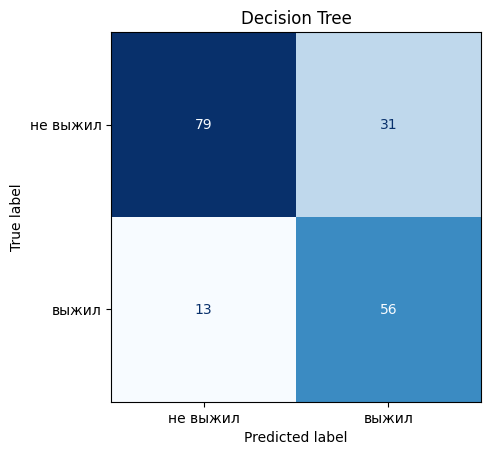

Accuracy     0.754
Precision    0.644
Recall       0.812
F1           0.718
F1_train     0.772
dtype: float64

In [8]:
gs = GridSearchCV(
    make_pipeline(
        prep(),
        DecisionTreeClassifier(random_state=RS, class_weight="balanced", max_depth=4),
    ),
    {"decisiontreeclassifier__max_depth": range(2, 9)},
    scoring="f1",
    cv=cv,
).fit(X_train, y_train)
print("Лучшая глубина по CV на train:", gs.best_params_["decisiontreeclassifier__max_depth"], "| F1 CV:", round(gs.best_score_, 3))
fit_eval("Decision Tree", gs.best_estimator_)

**Decision Tree и переобучение.** Дерево без ограничений хорошо подгоняется под обучающие данные, но на тесте F1 заметно ниже. Большой разрыв между train и test - признак **переобучения**: дерево запоминает обучающие объекты, в том числе шум, вместо того чтобы выучить общие закономерности.

Чтобы получить честную модель, глубина подобрана **кросс-валидацией на обучающей выборке**. Неглубокое дерево имеет близкие значения F1 на train и test, то есть признаков сильного переобучения нет, и по тесту качество не хуже, чем у дерева без ограничений. В итоговую таблицу идёт именно такое дерево.

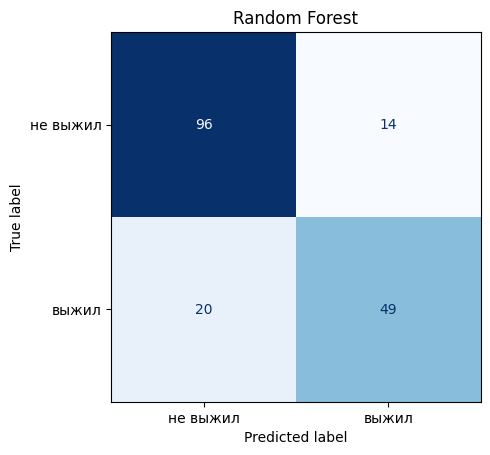

Accuracy     0.810
Precision    0.778
Recall       0.710
F1           0.742
F1_train     0.978
dtype: float64

In [9]:
fit_eval("Random Forest", make_pipeline(prep(), RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1)))

Случайный лес усредняет множество деревьев, обученных на разных подвыборках объектов и признаков, что снижает дисперсию и переобучение одиночного дерева. F1 на train у него высокий (каждое дерево глубокое), но разрыв с тестом компенсируется усреднением, и на тесте лес не хуже одиночного дерева. 

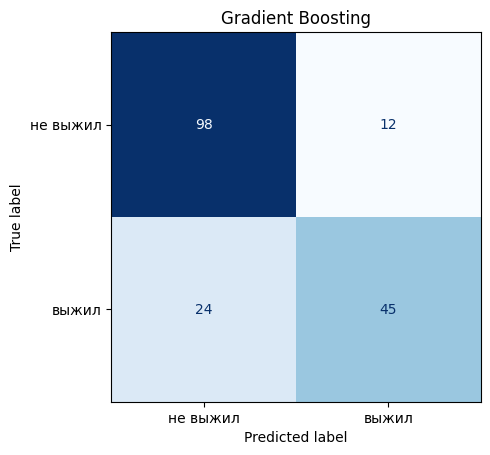

Accuracy     0.799
Precision    0.789
Recall       0.652
F1           0.714
F1_train     0.866
dtype: float64

In [10]:
fit_eval("Gradient Boosting", make_pipeline(prep(), GradientBoostingClassifier(random_state=RS)))

Градиентный бустинг строит неглубокие деревья последовательно: каждое исправляет ошибки предыдущих.

In [11]:
for name, est in [("SVM", SVC()), ("KNN", KNeighborsClassifier())]:
    for scale in (False, True):
        f1_cv = cross_val_score(make_pipeline(prep(scale), est), X_train, y_train, cv=cv, scoring="f1").mean()
        print(f"{name}, {'с масштабированием' if scale else 'без масштабирования'}: F1 CV (train) = {f1_cv:.3f}")

SVM, без масштабирования: F1 CV (train) = 0.445
SVM, с масштабированием: F1 CV (train) = 0.747
KNN, без масштабирования: F1 CV (train) = 0.584
KNN, с масштабированием: F1 CV (train) = 0.703


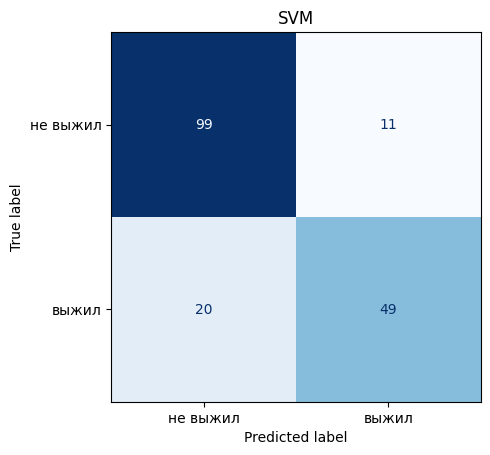

Accuracy     0.827
Precision    0.817
Recall       0.710
F1           0.760
F1_train     0.778
dtype: float64

In [12]:
fit_eval("SVM", make_pipeline(prep(scale=True), SVC()))

**Нужно ли масштабирование для SVM - да.** SVM сравнивает объекты через евклидово расстояние `exp(-γ·||x − x'||²)`. Если признаки в разных масштабах (`Fare` от 0 до 512, `Age` до 80, `Pclass` от 1 до 3, бинарные признаки 0/1), расстояние определяется в основном признаками с наибольшим разбросом (`Fare`, `Age`), а важный `Sex` почти не влияет. После `StandardScaler` вклад признаков сопоставим. Сравнение по кросс-валидации на train это подтверждает.

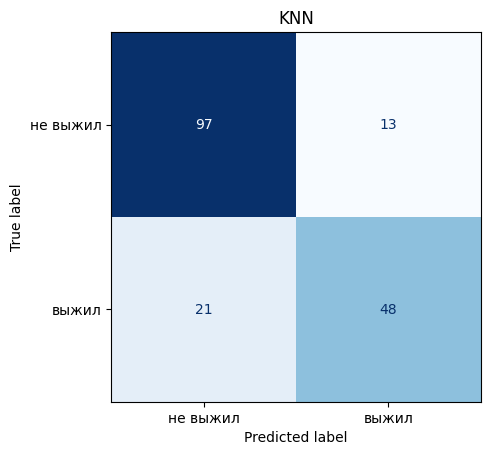

Accuracy     0.810
Precision    0.787
Recall       0.696
F1           0.738
F1_train     0.797
dtype: float64

In [13]:
fit_eval("KNN", make_pipeline(prep(scale=True), KNeighborsClassifier()))

**Почему масштаб особенно важен для KNN.** KNN не обучает параметров, а относит объект к классу большинства среди `k` ближайших соседей, где «близость» - евклидово расстояние. Если `Fare` измеряется сотнями, а `Sex` принимает значения 0 и 1, то разница в `Fare` перевешивает различие в поле, и соседи подбираются только по стоимости билета и возрасту; самый информативный признак фактически игнорируется. Масштабирование делает вклад признаков сопоставимым. 

# Честное сравнение моделей

- Все модели должны сравниваться в одинаковых условиях
- Составить итоговую таблицу с Accuracy, Precision, Recall и F1 для baseline и всех пяти моделей
- Определить, какие модели превзошли установленный порог качества

In [14]:
for name, model in fitted.items():
    res[name]["F1_CV"] = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1").mean() 

table = pd.DataFrame(res).T.sort_values("F1", ascending=False)
table["F1 > 0.70"] = table["F1"] > 0.70
table.round(3)

,Accuracy,Precision,Recall,F1,F1_train,F1_CV,F1 > 0.70
SVM,0.827,0.817,0.710,0.760,0.778,0.747,True
Random Forest,0.810,0.778,0.710,0.742,0.978,0.738,True
KNN,0.810,0.787,0.696,0.738,0.797,0.703,True
Decision Tree,0.754,0.644,0.812,0.718,0.772,0.737,True
Gradient Boosting,0.799,0.789,0.652,0.714,0.866,0.758,True
Baseline,0.615,0.000,0.000,0.000,0.000,0.000,False


Все модели обучены на одном `X_train` и оценены на одном `X_test` с одинаковым препроцессингом внутри пайплайна; колонка `F1_CV` - дополнительная оценка по 5-fold кросс-валидации на train (одни и те же фолды), без тестовой выборки.

**Порог F1 > 0.70.** Прошли все модели.

**Почему результаты различаются.**
- **Данные простые и маленькие.** Основной сигнал - `Sex`, `Pclass`, `Age`; число признаков невелико, объектов 891. Поэтому сложные модели почти не выигрывают у простого неглубокого дерева, а разница между лучшими моделями лежит в пределах шума оценки на тесте.
- **Ансамбли.** Усреднение (RF) и последовательное исправление ошибок (GB) уменьшают переобучение одиночного дерева.
- **SVM** строит гладкую нелинейную границу и при масштабировании работает на уровне ансамблей; без подбора параметров `C` и `γ` она не оптимальна.
- **KNN** чувствителен к шуму и к числу соседей, плохо работает с бинарными признаками (по ним расстояние меняется «скачком») и не умеет выделять главные признаки: все признаки вносят в расстояние равный вклад, хотя `Sex` информативнее остальных.
- **Переобучение** видно по `F1_train`: у леса и бустинга он значительно выше, чем F1 на тесте, но для ансамблей это нормально, а решающий показатель - качество на отложенных данных и в кросс-валидации.

# Feature Importance

Необходимо:
1. визуализировать важность признаков
2. выделить наиболее важные признаки
3. сравнить результаты Decision Tree, Random Forest и Gradient Boosting
4. сопоставить важность признаков с выводами, сделанными при первичном анализе данных

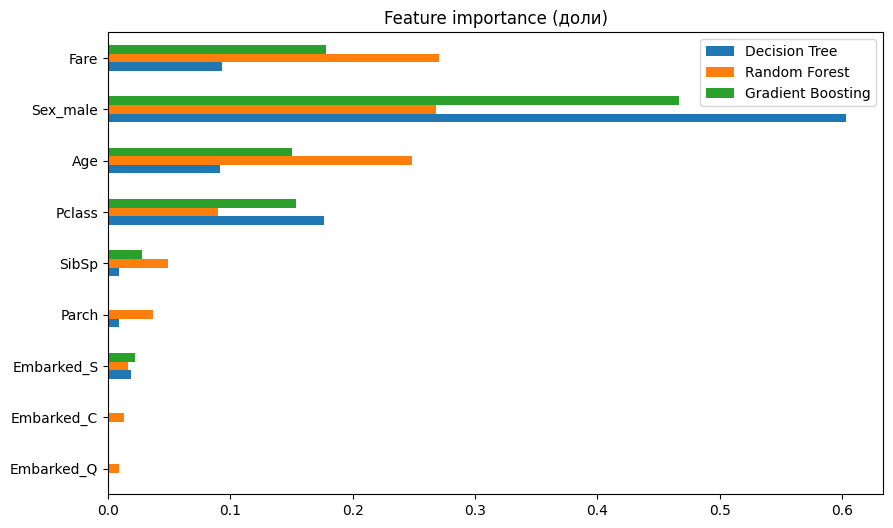

,Decision Tree,Random Forest,Gradient Boosting
Fare,0.093,0.270,0.178
Sex_male,0.603,0.268,0.466
Age,0.091,0.248,0.151
Pclass,0.176,0.090,0.153
SibSp,0.009,0.049,0.028
Parch,0.009,0.037,0.001
Embarked_S,0.019,0.016,0.022
Embarked_C,0.000,0.013,0.000
Embarked_Q,0.000,0.009,0.000


In [15]:
names = [n.split("__")[1] for n in fitted["Decision Tree"][0].get_feature_names_out()]  # fitted["Decision Tree"][0] — шаг препроцессинга
fi = pd.DataFrame({m: fitted[m][-1].feature_importances_ for m in ["Decision Tree", "Random Forest", "Gradient Boosting"]},
                  index=names).sort_values("Random Forest")  # Таблица важностей

fi.plot.barh(figsize=(10, 6), title="Feature importance (доли)")
plt.show()
fi.sort_values("Random Forest", ascending=False).round(3)

**Наиболее важные признаки.** У всех трёх моделей на первом месте `Sex_male`; признаки семьи (`SibSp`, `Parch`) и порта посадки (`Embarked_*`) значительно менее важны.

**Сравнение моделей.**
- *Decision Tree* опирается на небольшое число признаков: неглубокое дерево делает первое разбиение по `Sex`, затем по `Pclass` и `Age`, остальные признаки получают почти нулевую важность. Важность у одиночного дерева нестабильна: небольшое изменение выборки может изменить структуру дерева.
- *Random Forest* распределяет важность по большему числу признаков: `Sex` остаётся главным, но заметно выше важность `Age` и `Fare`. Усреднение по сотням деревьев делает оценку более стабильной. Кроме того, важность на основе уменьшения неопределённости (impurity) смещена в пользу непрерывных признаков с большим числом уникальных значений (`Age`, `Fare`), поэтому их роль у леса может быть завышена.
- *Gradient Boosting* по сравнению с лесом сильнее концентрирует важность на нескольких главных признаках (`Sex`, `Pclass`), так как последовательные деревья повторно используют самые сильные сигналы, а остальные признаки вносят лишь небольшие поправки.
- Итог: набор главных признаков у трёх моделей совпадает, различается лишь «вес» второстепенных.

**Сопоставление с первичным анализом.** Результат согласуется с EDA: `Sex` и `Pclass` показывали самые сильные различия в доле выживших; `Age` важен из-за более высокой доли выживших среди детей; `Fare` важен во многом потому, что тесно связан с `Pclass` (признаки частично дублируют друг друга, и важность делится между ними). Малая важность `Embarked` подтверждает вывод EDA: высокая доля выживших в Cherbourg была следствием состава пассажиров, а не самого порта.

**Можно ли утверждать, что важный для модели признак - причина выживания? Нет.**
1. Важность показывает, насколько признак помогает модели *предсказывать* на этих данных, а не что произойдёт, если признак изменить.
2. Признак может быть лишь косвенным показателем истинной причины. Сам по себе пол не «спасал» - выживаемость определялась правилом посадки в шлюпки («женщины и дети первыми») и поведением экипажа. Класс билета связан с расположением кают (ближе к палубе со шлюпками), статусом и доступом к шлюпкам.
3. Признаки скоррелированы (`Pclass` и `Fare`; `SibSp` и `Parch`), и важность между ними делится произвольно, а ранжирование зависит от модели.
4. Данные неполные: в них нет многих факторов (где находился пассажир, умел ли плавать, сколько времени было до лодок), а сам набор - выборка примерно 40% пассажиров, поэтому возможны скрытые общие причины и смещение отбора.

# Анализ ошибок

- Для лучшей модели исследовать confusion matrix подробнее
- Определить, какие типы ошибок встречаются чаще и для каких групп пассажиров модель ошибается наиболее заметно


Лучшая модель: Gradient Boosting
{'верно': 143, 'FN': 24, 'FP': 12}


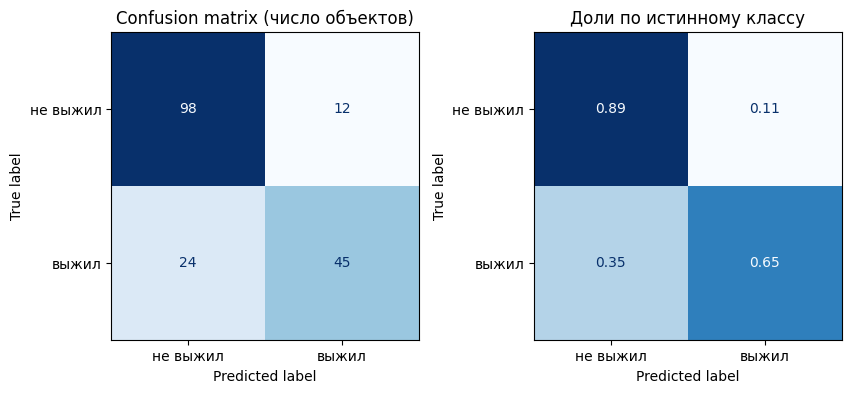

In [16]:
best = table.drop("Baseline")["F1_CV"].idxmax()
print("Лучшая модель:", best)

err = df.loc[X_test.index].assign(y_pred=preds[best])  # # df.loc[X_test.index] — исходные признаки тестовых объектов, .assign(y_pred=preds[best]) — добавляем столбец предсказаний
err["type"] = np.select([(err["Survived"] == 0) & (err["y_pred"] == 1), (err["Survived"] == 1) & (err["y_pred"] == 0)],
                        ["FP", "FN"], default="верно")
print(err["type"].value_counts().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, norm, t in [(ax[0], None, "Confusion matrix (число объектов)"), (ax[1], "true", "Доли по истинному классу")]:
    ConfusionMatrixDisplay.from_predictions(err["Survived"], err["y_pred"], normalize=norm, display_labels=["не выжил", "выжил"],
                                            cmap="Blues", colorbar=False, ax=a)
    a.set_title(t)
plt.show()

In [17]:
err["Возраст"] = pd.cut(err["Age"], [0, 12, 18, 60, 100], labels=["до 12", "12–18", "18–60", "60+"])
err["ошибка"] = err["type"] != "верно"
for c in ["Sex", "Pclass", "Возраст"]:
    display(err.groupby(c, observed=True)["ошибка"].agg(доля_ошибок="mean", n="size").round(2).T)  # observed=True — не создавать пустые категории
display(pd.crosstab([err["Sex"], err["Pclass"]], err["type"]))

Sex,female,male
доля_ошибок,0.21,0.19
n,61.00,118.00


Pclass,1,2,3
доля_ошибок,0.24,0.12,0.21
n,45.00,34.00,100.00


Возраст,до 12,12–18,18–60,60+
доля_ошибок,0.29,0.06,0.2,0.17
n,14.00,17.00,102.0,6.00


type           FN  FP  верно
Sex    Pclass               
female 1        0   1     14
       2        0   1     17
       3        7   4     17
male   1        5   5     20
       2        3   0     13
       3        9   1     62

In [18]:
err[err["ошибка"]].sample(8, random_state=RS)[["Name", "Sex", "Age", "Pclass", "SibSp", "Parch", "Fare", "Survived", "y_pred", "type"]]

,Name,Sex,Age,Pclass,SibSp,Parch,Fare,Survived,y_pred,type
295,"Lewy, Mr. Ervin G",male,NaN,1,0,0,27.7208,0,1,FP
17,"Williams, Mr. Charles Eugene",male,NaN,2,0,0,13.0000,1,0,FN
444,"Johannesen-Bratthammer, Mr. Bernt",male,NaN,3,0,0,8.1125,1,0,FN
39,"Nicola-Yarred, Miss. Jamila",female,14.0,3,1,0,11.2417,1,0,FN
501,"Canavan, Miss. Mary",female,21.0,3,0,0,7.7500,0,1,FP
823,"Moor, Mrs. (Beila)",female,27.0,3,0,1,12.4750,1,0,FN
23,"Sloper, Mr. William Thompson",male,28.0,1,0,0,35.5000,1,0,FN
502,"O'Sullivan, Miss. Bridget Mary",female,NaN,3,0,0,7.6292,0,1,FP


In [19]:
Xi = lambda X_: X_.assign(PassengerId=df.loc[X_.index, "PassengerId"])  # добавляет к DataFrame столбец PassengerId, взятый из df по индексу
rf_id = make_pipeline(prep(num=num + ["PassengerId"]), RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1))
rf_id.fit(Xi(X_train), y_train)

n_id = [n.split("__")[1] for n in rf_id[0].get_feature_names_out()]
imp = pd.Series(rf_id[-1].feature_importances_, index=n_id).sort_values(ascending=False)
print(f"RF + PassengerId: F1 train = {f1_score(y_train, rf_id.predict(Xi(X_train))):.3f}, F1 test = {f1_score(y_test, rf_id.predict(Xi(X_test))):.3f}"
      f" | RF без PassengerId: F1 train = {res['Random Forest']['F1_train']:.3f}, F1 test = {res['Random Forest']['F1']:.3f}")
print("Важность PassengerId:", round(imp["PassengerId"], 3), "| место:", list(imp.index).index("PassengerId") + 1, "из", len(imp))

RF + PassengerId: F1 train = 1.000, F1 test = 0.733 | RF без PassengerId: F1 train = 0.978, F1 test = 0.742
Важность PassengerId: 0.189 | место: 3 из 10


**Типы ошибок.** Матрица ошибок показывает соотношение FP и FN. У лучшей модели ошибок типа FN (24) в два раза больше, чем FP (12). Модель чаще пропускает выживших, чем ошибочно называет погибших выжившими.

**Для каких групп ошибок больше.** По таблицам видно, что модель почти не ошибается на женщинах 1–2 классов (≈ 6% ошибок). А вот на мужчинах 3-го класса ошибок достаточно много (10 из 72 = 14%) - в основном это FN: выжившие мужчины 3-го класса, которых модель отнесла к массе погибших. Мужчины 1-го класса тоже проблемные: 10 ошибок из 30 (33%).

**Объекты с ошибками.** Типичные причины:
- FN: взрослый мужчина 1-го класса или мальчик, которого модель отнесла к основной массе погибших мужчин; на его исход повлияли обстоятельства, которых нет в данных (место на палубе, помощь экипажа);
- FP - это в основном женщины 3-го класса, которые погибли, хотя по общему правилу «женщина → выживет». Часто это пассажирки, ехавшие одни или с малым числом родственников, и модель не имеет признака, который бы выделил их особый случай.
- ошибки у пассажиров с заполненным медианой `Age`: настоящий возраст неизвестен, и модель опирается на «среднего» пассажира.

В обоих случаях ошибка отражает не «плохую» модель, а то, что в доступных признаках нет информации, которая определила исход.

**Проверка на идентифицирующие признаки и утечки.**
- В итоговый набор признаков не входят `PassengerId`, `Name`, `Ticket` и `Cabin`, то есть модели не могут «узнавать» конкретных пассажиров и не используют информацию, появившуюся после события (`Cabin`).
- Эксперимент выше показывает риск: если добавить `PassengerId`, случайный лес даёт ему ненулевую важность (признак уникален и позволяет «выделять» объекты), F1 на train вырастает, а на тесте не улучшается. То есть такие признаки приводят лишь к запоминанию. Хорошее качество моделей объясняется содержательными признаками (`Sex`, `Pclass`, `Age`), а не идентификаторами.
- Остаточный риск есть у `Fare` и `Age`: у них много уникальных значений, и глубокое дерево может использовать их для запоминания; именно поэтому для дерева подбирается глубина по кросс-валидации.

# Общий вывод

Все модели превзошли baseline и прошли порог F1 > 0.70. Главные признаки у всех моделей - `Sex`, `Pclass`, `Age`, `Fare`, и это ассоциации, а не причины выживания. Одиночное дерево без ограничений переобучается; регуляризация (глубина по CV) и ансамбли решают проблему. Основные ошибки приходятся на группы с «неопределённым» исходом (женщины 3-го класса, мужчины 1-го класса, дети), информации о которых в признаках недостаточно.